# Week 3 — V1 Data Pipeline · EventLayout-RL

**What this notebook does, in plain words:** it takes a folder of images, checks that each one opens, makes a clean prepared copy, checks the copies, and writes a record (a *manifest*) of which source file became which output. Running it a second time must give exactly the same result.

**Which data:** this project's real floor-plan images do not exist yet, so the notebook uses the **synthetic practice images** from the Topic 3 Dummy Dataset Pack (`03_images`: 6 PNG files + `labels.csv`). They are a good stand-in: like the project's colour-coded floor plans, each image uses only a few pure colours (white plus red or blue). They will later be replaced by self-made colour-coded floor plans (black = walls, red = pillars, green = exits, blue = power points).

> ⚠️ **Practice data only.** Nothing in this notebook shows how well EventLayout-RL performs.

**How to run in Google Colab**
1. Run **Cell 1** (it creates the folders).
2. In the Files panel, upload `Topic_3_Dummy_Datasets.zip` into `week3_project/data/raw`.
3. Run the remaining cells in order (Runtime → Run all also works after the upload).

*The notebook uses Colab's standard folder `/content/week3_project`. The saved outputs below come from a local run, where the same folder was set to `week3_project` through the `WEEK3_BASE_DIR` setting; nothing else changes.*

Related documents: [data inventory](../docs/week3_data_inventory.md) · [pipeline decisions](../docs/week3_pipeline_decisions.md) · [pipeline diagram](../docs/week3_pipeline_diagram.png)

## Part A — Start with the data

**A1 · Which requirements need this data** (from `docs/week2_requirements.md`)

| Requirement | What it needs from the data | Practice stand-in |
|---|---|---|
| **FR1 / NFR2** — read the floor-plan image into a correct grid map | Images whose colours can be read exactly, plus an "answer" for each image to check the reading against | The 6 shape images and `labels.csv` (the colour of each shape) |
| **RAI2** — the user checks the map; mistakes must be traceable | Knowing exactly which file (and which version) produced each output | SHA-256 fingerprints and the lineage manifest |

**A2 · Set up the workspace** — run Cell 1 first, and again after any runtime restart.

In [1]:
# Cell 1 — Workspace setup (RUN FIRST)
import os
from pathlib import Path

# Colab standard folder. WEEK3_BASE_DIR only lets the same notebook run outside Colab.
BASE_DIR = Path(os.environ.get("WEEK3_BASE_DIR", "/content/week3_project"))
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Compatibility aliases for notebook examples
RAW = RAW_DIR
PROCESSED = PROCESSED_DIR
BASE = BASE_DIR
OUT = PROCESSED_DIR

print("Raw folder:", RAW_DIR)
print("Processed folder:", PROCESSED_DIR)

Raw folder: week3_project/data/raw
Processed folder: week3_project/data/processed


**Now upload** `Topic_3_Dummy_Datasets.zip` into `week3_project/data/raw`, then run Cell 2 to unzip it.

In [2]:
# Cell 2 — Extract practice ZIP (OPTIONAL: only because we use the dummy dataset)
from zipfile import ZipFile

zip_path = RAW_DIR / "Topic_3_Dummy_Datasets.zip"

if zip_path.is_file():
    with ZipFile(zip_path) as zf:
        zf.extractall(RAW_DIR)
    print("Dummy dataset pack extracted.")
    print("Location:", RAW_DIR / "topic3_dummy_datasets")
else:
    print("No ZIP found.")
    print("Continue with your separately uploaded project files.")

Dummy dataset pack extracted.
Location: week3_project/data/raw/topic3_dummy_datasets


In [3]:
# Cell 3 — Verify uploaded inputs (self-contained)
import os
from pathlib import Path

RAW = Path(os.environ.get("WEEK3_BASE_DIR", "/content/week3_project")) / "data" / "raw"
RAW_DIR = RAW
BASE_DIR = RAW.parent.parent
PROCESSED_DIR = BASE_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
BASE = BASE_DIR
OUT = PROCESSED_DIR

files = sorted(f for f in RAW.rglob("*") if f.is_file())
print("Input count:", len(files))
for f in files:
    print(f.relative_to(RAW), "bytes:", f.stat().st_size)

assert files, "Upload at least one relevant input file before proceeding."
print("Upload verified. Select your relevant input(s) for Step A3.")

Input count: 17
Topic_3_Dummy_Datasets.zip bytes: 9296
topic3_dummy_datasets/01_documents/faq_demo.txt bytes: 171
topic3_dummy_datasets/01_documents/student_handbook_demo.pdf bytes: 1705
topic3_dummy_datasets/02_tabular/student_performance_demo.csv bytes: 210
topic3_dummy_datasets/03_images/labels.csv bytes: 182
topic3_dummy_datasets/03_images/shape_01.png bytes: 483
topic3_dummy_datasets/03_images/shape_02.png bytes: 315
topic3_dummy_datasets/03_images/shape_03.png bytes: 538
topic3_dummy_datasets/03_images/shape_04.png bytes: 360
topic3_dummy_datasets/03_images/shape_05.png bytes: 588
topic3_dummy_datasets/03_images/shape_06.png bytes: 404
topic3_dummy_datasets/04_json_api/products_api_demo.json bytes: 608
topic3_dummy_datasets/05_audio/labels.csv bytes: 59
topic3_dummy_datasets/05_audio/tone_high.wav bytes: 16044
topic3_dummy_datasets/05_audio/tone_low.wav bytes: 16044
topic3_dummy_datasets/06_timeseries/energy_readings_demo.csv bytes: 185
topic3_dummy_datasets/README.md bytes: 2410

**A3 · Inspect the selected data.** The pack contains six pathways; only `03_images` matches this project (floor plans are images). A "file loaded" message is not evidence, so we look at the actual pictures, sizes, colour modes and colours, and check that every image has a label.

Labels file: topic3_dummy_datasets/03_images/labels.csv
Columns: ['filename', 'shape_label', 'colour'] | rows: 6
    filename shape_label colour
shape_01.png      circle    red
shape_02.png      square   blue
shape_03.png      circle   blue
shape_04.png      square    red
shape_05.png      circle    red
shape_06.png      square   blue

shape_01.png: size=(92, 97) (width x height), mode=RGB, format=PNG
  colours (R,G,B) -> pixels: {(255, 0, 0): 1804, (255, 255, 255): 7120}
  label: {'filename': 'shape_01.png', 'shape_label': 'circle', 'colour': 'red'}

shape_06.png: size=(152, 132) (width x height), mode=RGB, format=PNG
  colours (R,G,B) -> pixels: {(0, 0, 255): 2304, (255, 255, 255): 17760}
  label: {'filename': 'shape_06.png', 'shape_label': 'square', 'colour': 'blue'}


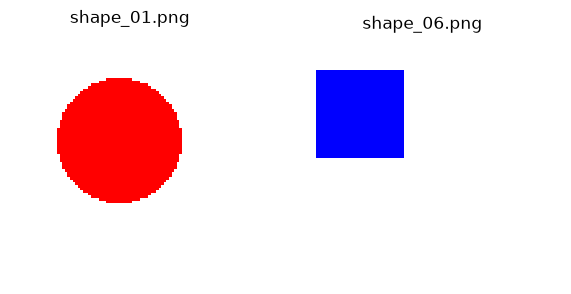


Images without a label / labels without an image: none


In [4]:
# Cell A3 — Inspect two representative images and the labels
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

image_folder = RAW_DIR / "topic3_dummy_datasets" / "03_images"
labels_path = image_folder / "labels.csv"

labels = pd.read_csv(labels_path)
print("Labels file:", labels_path.relative_to(RAW_DIR))
print("Columns:", list(labels.columns), "| rows:", len(labels))
print(labels.to_string(index=False))


def colour_counts(img):
    # Return {(R, G, B): number of pixels} for a PIL image
    pixels = np.asarray(img.convert("RGB")).reshape(-1, 3)
    colours, counts = np.unique(pixels, axis=0, return_counts=True)
    return {tuple(int(v) for v in c): int(n) for c, n in zip(colours, counts)}


samples = ["shape_01.png", "shape_06.png"]  # the smallest and the largest image
fig, axes = plt.subplots(1, len(samples), figsize=(6, 3))
for ax, name in zip(axes, samples):
    with Image.open(image_folder / name) as im:
        print(f"\n{name}: size={im.size} (width x height), mode={im.mode}, format={im.format}")
        print("  colours (R,G,B) -> pixels:", colour_counts(im))
        ax.imshow(im.convert("RGB"), interpolation="nearest")
    print("  label:", labels.loc[labels.filename == name].to_dict("records")[0])
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

on_disk = {p.name for p in image_folder.glob("*.png")}
print("\nImages without a label / labels without an image:", (set(labels.filename) ^ on_disk) or "none")

**What the inspection shows**
- All 6 images open, are PNG and already RGB, but **sizes differ** (92×97 up to 152×132 pixels).
- Each image uses **exactly 2 pure colours**: white `(255,255,255)` and red `(255,0,0)` or blue `(0,0,255)` — just like a colour-coded floor plan.
- `labels.csv` has one row per image (`filename`, `shape_label`, `colour`), so every image has an "answer" to check against.

## Part B — Prepare the data

**Cell 4** gives three helpers: pick an exact source file, compute its SHA-256 fingerprint, and save the lineage manifest. **Cell 4A** starts an empty list of "source → output" links.

In [5]:
# Cell 4 — REQUIRED: Source Selection + Lineage Utilities
from pathlib import Path
import json
import hashlib
from datetime import datetime, timezone

# Select the exact source before parsing.
# Never automatically take the first file by extension.


def select_source(relative_path=None, filename=None, suffixes=None):
    if relative_path:
        selected = RAW_DIR / relative_path
        if not selected.is_file():
            raise FileNotFoundError(f"Source not found: {selected}")
        return selected
    matches = sorted(
        p for p in RAW_DIR.rglob("*")
        if p.is_file()
        and (filename is None or p.name == filename)
        and (suffixes is None or p.suffix.lower() in suffixes)
    )
    print("Candidates:", [str(p.relative_to(RAW_DIR)) for p in matches])
    if len(matches) != 1:
        raise ValueError("Select exactly one source. Set relative_path to an exact file under RAW_DIR.")
    return matches[0]


def source_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def save_manifest(records):
    manifest = {
        "pipeline_version": "week3-v1",
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "records": records,
    }
    target = BASE_DIR / "data" / "week3_manifest.json"
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Saved lineage:", target)
    return manifest


print("Cell 4 completed successfully.")
print("Source selection and lineage utilities are ready.")
print("Available functions:")
print("- select_source()")
print("- source_hash()")
print("- save_manifest()")

Cell 4 completed successfully.
Source selection and lineage utilities are ready.
Available functions:
- select_source()
- source_hash()
- save_manifest()


In [6]:
# Cell 4A — COMMON LINEAGE REGISTRY (run once before the selected pathway)
from pathlib import Path

lineage_entries = {}


def register_lineage(source, output, processing):
    source = Path(source).resolve()
    output = Path(output).resolve()
    if not source.is_file():
        raise FileNotFoundError(f"Source file not found: {source}")
    if not output.is_file():
        raise FileNotFoundError(f"Prepared output not found: {output}")
    if output.stat().st_size == 0:
        raise ValueError(f"Prepared output is empty: {output}")
    if not isinstance(processing, str) or not processing.strip():
        raise ValueError("A processing description is required.")
    processing = processing.strip()
    if processing.upper().startswith("REPLACE"):
        raise ValueError("Replace the placeholder with the actual method.")
    # Ensure source and output belong to the project workspace
    source.relative_to(RAW_DIR.resolve())
    output.relative_to(PROCESSED_DIR.resolve())
    # Same source/output pair is updated, not duplicated
    key = (str(source), str(output))
    lineage_entries[key] = {"source": source, "output": output, "processing": processing}
    print("Registered:", source.name, "->", output.name)


print("Common lineage registry ready.")
print("Registered entries:", len(lineage_entries))

Common lineage registry ready.
Registered entries: 0


**B1–B2 · Pathway C (images).** Settings chosen for this project, justified by the comparison in B3:
- `CONVERT_TO_RGB = True` — every image gets the same 3-channel colour format, so colours can be compared exactly.
- `TARGET_SIZE = None` — **no resizing**. Resizing blends neighbouring colours and squashes the room's proportions (see B3).
- The labels from `labels.csv` are carried into the image manifest by filename, so each prepared image keeps its "answer".

In [7]:
# Cell 5C — PATHWAY C — IMAGE DATA (settings chosen in B3)
from PIL import Image, UnidentifiedImageError
import pandas as pd

# Step 1: Select the source image folder (practice data; replaced later by real floor plans)
source_dir = RAW_DIR / "topic3_dummy_datasets" / "03_images"
assert source_dir.is_dir(), f"Choose an existing image folder: {source_dir}"

# Step 2: Collect supported image files
image_files = sorted(
    p for p in source_dir.iterdir()
    if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg", ".webp"}
)
assert image_files, "No images found in the selected folder"
print("--- Source Image Folder ---")
print("Folder:", source_dir)
print("Image count:", len(image_files))
print("Example files:", [p.name for p in image_files[:5]])

# Step 3: Preparation settings (chosen in Step B3)
TARGET_SIZE = None       # keep original size: resizing mixes colours
CONVERT_TO_RGB = True    # one consistent colour format

labels = pd.read_csv(source_dir / "labels.csv").set_index("filename")

# Step 4: Prepare output folder
image_dir = PROCESSED_DIR / "images"
image_dir.mkdir(parents=True, exist_ok=True)
rows = []
failed_files = []

# Step 5: Process images
for f in image_files:
    try:
        with Image.open(f) as im:
            im.load()
            original_size = im.size
            original_mode = im.mode
            transformed = im.convert("RGB") if CONVERT_TO_RGB else im.copy()
            if TARGET_SIZE is not None:
                transformed = transformed.resize(TARGET_SIZE)
            target = image_dir / f"{f.stem}_{source_hash(f)[:12]}.png"
            transformed.save(target)  # PNG = lossless, colours are kept exactly
        has_label = f.name in labels.index
        if not has_label:
            print("WARNING: no label for", f.name)
        rows.append({
            "source": str(f.relative_to(RAW_DIR)),
            "source_sha256": source_hash(f),
            "original_width": original_size[0],
            "original_height": original_size[1],
            "original_mode": original_mode,
            "output": str(target.relative_to(BASE_DIR)),
            "output_width": transformed.size[0],
            "output_height": transformed.size[1],
            "shape_label": labels.at[f.name, "shape_label"] if has_label else "MISSING",
            "colour_label": labels.at[f.name, "colour"] if has_label else "MISSING",
            "processing": f"convert_to_rgb={CONVERT_TO_RGB}; resize={TARGET_SIZE}; labels joined by filename",
        })
    except (UnidentifiedImageError, OSError) as err:
        failed_files.append({"file": f.name, "error": str(err)})
        print("Failed:", f.name, "|", str(err))

# Step 6: Validate processing results
assert rows, "No readable images were prepared"
prepared_path = PROCESSED_DIR / "image_manifest.csv"
pd.DataFrame(rows).to_csv(prepared_path, index=False)
assert prepared_path.is_file(), "Image manifest was not created"
assert prepared_path.stat().st_size > 0, "Image manifest is empty"

# Step 7: Show evidence
print("\n--- Preparation Summary ---")
print("Images prepared:", len(rows))
print("Images failed:", len(failed_files))
print("Prepared image folder:", image_dir)
print("Manifest:", prepared_path)
manifest_df = pd.read_csv(prepared_path)
print("\nManifest preview:")
print(manifest_df.drop(columns=["source_sha256", "processing"]).to_string(index=False))

# Preserve the image folder reference for Step B4
f = source_dir
print("\nPATHWAY C completed successfully.")

--- Source Image Folder ---
Folder: week3_project/data/raw/topic3_dummy_datasets/03_images
Image count: 6
Example files: ['shape_01.png', 'shape_02.png', 'shape_03.png', 'shape_04.png', 'shape_05.png']

--- Preparation Summary ---
Images prepared: 6
Images failed: 0
Prepared image folder: week3_project/data/processed/images
Manifest: week3_project/data/processed/image_manifest.csv

Manifest preview:
                                      source  original_width  original_height original_mode                                          output  output_width  output_height shape_label colour_label
topic3_dummy_datasets/03_images/shape_01.png              92               97           RGB data/processed/images/shape_01_17a1e2828014.png            92             97      circle          red
topic3_dummy_datasets/03_images/shape_02.png             104              104           RGB data/processed/images/shape_02_dfa0925ff27b.png           104            104      square         blue
topic3_dummy_da

**B3 · Validate the prepared result.** First the basic output contract (the file exists and is not empty). A non-empty file is not proof of correct content, so we also open every prepared image and compare it with its source, pixel by pixel.

In [8]:
# B3 — Basic output contract (REQUIRED)
assert prepared_path.exists(), 'Prepared output missing.'
assert prepared_path.stat().st_size > 0, 'Prepared output is empty.'
print('Output:', prepared_path, 'Size:', prepared_path.stat().st_size)
print('Validation: file exists and is non-empty; verify content manually too.')

# Content check: each prepared image must have the same size and pixels as its source
identical = 0
for row in rows:
    with Image.open(RAW_DIR / row["source"]) as src, Image.open(BASE_DIR / row["output"]) as out:
        same = src.size == out.size and np.array_equal(np.asarray(src.convert("RGB")), np.asarray(out))
    identical += same
    if not same:
        print("CHANGED:", row["source"])
print(f"Prepared images identical to their source (pixels and size): {identical}/{len(rows)}")
assert identical == len(rows), "A prepared image differs from its source."

Output: week3_project/data/processed/image_manifest.csv Size: 1629
Validation: file exists and is non-empty; verify content manually too.
Prepared images identical to their source (pixels and size): 6/6


**B3 · Compare two preparation settings on the same images**
- **Setting A** — the lab's example setting: convert to RGB **and resize to 224×224**.
- **Setting B** — this project's choice: convert to RGB, **keep the original size**.

We measure what matters for a colour-coded floor plan: how many colours the image has, how many pixels get a colour that was **not** in the original ("mixed" pixels), and whether the width/height ratio (the room's proportions) is kept.

       image                 setting size (w x h)  w/h ratio  original ratio  colours  mixed pixels %
shape_01.png A: RGB + resize 224x224    224 x 224      1.000           0.948      231            2.02
shape_01.png   B: RGB, original size      92 x 97      0.948           0.948        2            0.00
shape_02.png A: RGB + resize 224x224    224 x 224      1.000           1.000       28            1.64
shape_02.png   B: RGB, original size    104 x 104      1.000           1.000        2            0.00
shape_03.png A: RGB + resize 224x224    224 x 224      1.000           1.045      204            1.34
shape_03.png   B: RGB, original size    116 x 111      1.045           1.045        2            0.00
shape_04.png A: RGB + resize 224x224    224 x 224      1.000           1.085       14            1.03
shape_04.png   B: RGB, original size    128 x 118      1.085           1.085        2            0.00
shape_05.png A: RGB + resize 224x224    224 x 224      1.000           1.120      

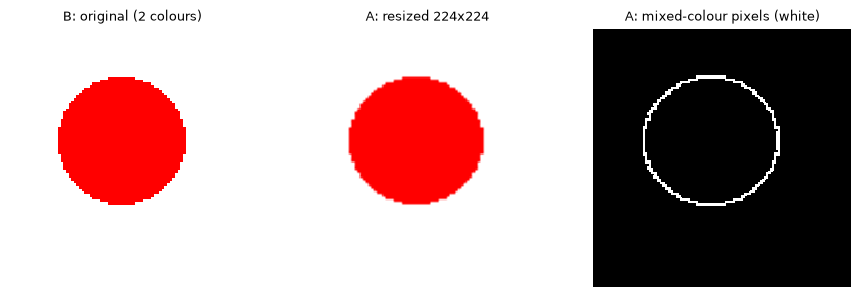

In [9]:
# Cell B3 — Compare Setting A (resize 224x224) with Setting B (original size)


def colour_codes(img):
    # Encode each pixel's (R, G, B) as one integer so colours can be compared quickly
    a = np.asarray(img.convert("RGB")).reshape(-1, 3).astype(np.int64)
    return a[:, 0] * 65536 + a[:, 1] * 256 + a[:, 2]


comparison = []
for f in image_files:
    with Image.open(f) as im:
        original = im.convert("RGB")
    palette = np.unique(colour_codes(original))
    settings = {"A: RGB + resize 224x224": original.resize((224, 224)),
                "B: RGB, original size": original}
    for setting, img in settings.items():
        codes = colour_codes(img)
        comparison.append({
            "image": f.name,
            "setting": setting,
            "size (w x h)": f"{img.size[0]} x {img.size[1]}",
            "w/h ratio": round(img.size[0] / img.size[1], 3),
            "original ratio": round(original.size[0] / original.size[1], 3),
            "colours": len(np.unique(codes)),
            "mixed pixels %": round(100 * float(np.mean(~np.isin(codes, palette))), 2),
        })

cmp = pd.DataFrame(comparison)
print(cmp.to_string(index=False))

print("\n--- Summary per setting ---")
summary = cmp.groupby("setting").agg(
    max_colours=("colours", "max"),
    mean_mixed_pct=("mixed pixels %", "mean"),
    max_mixed_pct=("mixed pixels %", "max"),
    ratio_kept=("w/h ratio", lambda s: bool((s.values == cmp.loc[s.index, "original ratio"].values).all())),
)
print(summary.round(2).to_string())

# Show where the mixed pixels appear for one image
with Image.open(image_folder / "shape_01.png") as im:
    original = im.convert("RGB")
resized = original.resize((224, 224))
mixed = ~np.isin(colour_codes(resized), np.unique(colour_codes(original))).reshape(224, 224)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, img, title in [(axes[0], original, "B: original (2 colours)"),
                       (axes[1], resized, "A: resized 224x224"),
                       (axes[2], mixed, "A: mixed-colour pixels (white)")]:
    ax.imshow(img, interpolation="nearest", cmap="gray" if img is mixed else None)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Decision:** use **Setting B** (convert to RGB, keep original size).
- **Evidence:** Setting A turns 2 clean colours into up to **231** colours, makes **0.75–2.02%** of pixels (mean 1.3%) mixed colours in a ring around every shape edge, and changes the width/height ratio of **5 of 6** images (only the square one is unchanged). Setting B keeps exactly **2** colours, **0%** mixed pixels and the original ratio, and the content check above shows the prepared copies are pixel-identical (6/6).
- **Why it matters for this project (FR1 / NFR2):** the floor-plan reader decides what each square is by its exact colour. A blended edge pixel (red + white = pink) matches no colour in the code, so squares near walls and pillars would be misread, and a squashed image gives the wrong room proportions.
- **Accepted limitation:** prepared images keep different sizes, so later steps must handle any size (the floor-plan reader will convert each image to the 1 m grid using its own scale).

**B4 · Record lineage.** Link every source image to its prepared copy, and `labels.csv` to the image manifest that now carries the labels. Then save and verify the common manifest.

In [10]:
# B4.1 — Register Pathway C (images) + the labels
for row in rows:
    register_lineage(
        source=RAW_DIR / row["source"],
        output=BASE_DIR / row["output"],
        processing=row["processing"],
    )

register_lineage(
    source=source_dir / "labels.csv",
    output=prepared_path,
    processing="labels.csv joined into image_manifest.csv by filename (shape_label, colour)",
)
print("Registered entries:", len(lineage_entries))

Registered: shape_01.png -> shape_01_17a1e2828014.png
Registered: shape_02.png -> shape_02_dfa0925ff27b.png
Registered: shape_03.png -> shape_03_bb10030d1f0b.png
Registered: shape_04.png -> shape_04_2514fccc54d1.png
Registered: shape_05.png -> shape_05_94d4f1150747.png
Registered: shape_06.png -> shape_06_5908f2d0dabc.png
Registered: labels.csv -> image_manifest.csv
Registered entries: 7


In [11]:
# Cell 6A — GENERATE COMMON LINEAGE MANIFEST
assert lineage_entries, "No lineage entries registered. Register at least one selected pathway first."
lineage_records = []

for i, entry in enumerate(lineage_entries.values(), 1):
    source = entry["source"]
    output = entry["output"]
    processing = entry["processing"]
    # Validate registered files again
    assert source.is_file(), f"Missing source: {source}"
    assert output.is_file(), f"Missing output: {output}"
    assert output.stat().st_size > 0, "Empty output"
    lineage_records.append({
        "source_id": f"S{i:02d}",
        "source_filename": str(source.relative_to(RAW_DIR.resolve())),
        "source_sha256": source_hash(source),
        "prepared_output": str(output.relative_to(BASE_DIR.resolve())),
        "prepared_sha256": source_hash(output),
        "processing_note": processing,
        "source_version": "Topic 3 Dummy Dataset Pack (synthetic practice data)",
        "access_rights": "Course teaching material; synthetic, no personal data",
        "status": "Prepared; quality review pending",
    })

manifest = save_manifest(lineage_records)

print("\nCOMMON LINEAGE MANIFEST GENERATED")
print("Total lineage entries:", len(manifest["records"]))
print("Saved to:", BASE_DIR / "data" / "week3_manifest.json")

Saved lineage: week3_project/data/week3_manifest.json

COMMON LINEAGE MANIFEST GENERATED
Total lineage entries: 7
Saved to: week3_project/data/week3_manifest.json


In [12]:
# Cell 6B — VERIFY COMMON LINEAGE MANIFEST
import json

manifest_path = BASE_DIR / "data" / "week3_manifest.json"
assert manifest_path.is_file(), "Common lineage manifest not found."

with manifest_path.open("r", encoding="utf-8") as file:
    saved_manifest = json.load(file)

saved_records = saved_manifest.get("records", [])
assert saved_records, "No lineage records found in saved manifest."
assert len(saved_records) == len(lineage_entries), "Saved lineage count does not match registration."

for record in saved_records:
    source = RAW_DIR / record["source_filename"]
    output = BASE_DIR / record["prepared_output"]
    assert source.is_file(), f"Missing source: {source}"
    assert output.is_file(), f"Missing output: {output}"
    assert source_hash(source) == record["source_sha256"], f"Source checksum mismatch: {source}"
    assert source_hash(output) == record["prepared_sha256"], f"Prepared output checksum mismatch: {output}"

print("COMMON LINEAGE VALIDATION: PASS")
print("Verified records:", len(saved_records))
print("Manifest:", manifest_path)

COMMON LINEAGE VALIDATION: PASS
Verified records: 7
Manifest: week3_project/data/week3_manifest.json


## Part C — The V1 data pipeline

Part B explored the steps one by one. Part C runs the **same steps with the same settings** as one repeatable pipeline: **ingest → inspect → prepare/store → validate → record lineage**. Cell 9 then runs it a second time and checks that nothing changed.

In [13]:
# Cell 7 — REQUIRED: Common V1 Pipeline Utilities
import os
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

# Step 1: Define standard project paths (Colab default; see Cell 1)
BASE_DIR = Path(os.environ.get("WEEK3_BASE_DIR", "/content/week3_project"))
RAW_DIR = BASE_DIR / "data" / "raw"
PIPE_DIR = BASE_DIR / "data" / "pipeline_v1"
PIPE_DIR.mkdir(parents=True, exist_ok=True)

# Store registered pipeline runs for repeatability verification
PIPELINE_RUNS = {}


# Step 2: Calculate SHA-256 checksum
def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


# Step 3: Resolve an explicitly selected source
def resolve_source(relative_path, folder=False):
    source = RAW_DIR / relative_path
    if folder:
        if not source.is_dir():
            raise FileNotFoundError(f"Source folder not found: {source}")
    else:
        if not source.is_file():
            raise FileNotFoundError(f"Source file not found: {source}")
    return source


# Step 4: Execute the selected V1 data pipeline
def execute_pipeline(kind, source, inspect_fn, prepare_fn, configuration):
    source = Path(source)

    # INGEST: Identify relevant source files
    if kind == "images":
        inputs = sorted(
            p for p in source.iterdir()
            if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg", ".webp"}
        )
    else:
        inputs = [source]
    if not inputs or any(not p.is_file() for p in inputs):
        raise ValueError("No valid source files to ingest.")

    # INSPECT: Apply data-type-specific inspection
    inspection = inspect_fn(inputs, configuration)

    output_dir = PIPE_DIR / kind
    output_dir.mkdir(parents=True, exist_ok=True)

    # PREPARE / STORE: Apply selected transformation
    outputs, mappings, method = prepare_fn(inputs, output_dir, configuration)
    outputs = [Path(p) for p in outputs]

    # VALIDATE: Check prepared outputs
    if not outputs:
        raise ValueError("No prepared outputs were produced.")
    for output in outputs:
        if not output.is_file():
            raise FileNotFoundError(f"Prepared output missing: {output}")
        if output.stat().st_size == 0:
            raise ValueError(f"Prepared output is empty: {output}")

    validation = {
        "output_count": len(outputs),
        "output_sha256": [sha256_file(p) for p in outputs],
        "output_bytes": [p.stat().st_size for p in outputs],
    }

    # RECORD LINEAGE: Create pipeline execution record
    record = {
        "pipeline_version": "week3-v1",
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_type": kind,
        "configuration": configuration,
        "processing_method": method,
        "sources": [{"path": str(p), "sha256": sha256_file(p)} for p in inputs],
        "outputs": [str(p) for p in outputs],
        "source_output_mapping": mappings,
        "inspection": inspection,
        "validation": validation,
        "source_version": "Topic 3 Dummy Dataset Pack (synthetic practice data)",
        "access_rights": "Course teaching material; synthetic, no personal data",
    }

    manifest_path = output_dir / "pipeline_manifest.json"
    manifest_path.write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8")

    print(f"SUCCESS: {kind} | Inputs: {len(inputs)} | Outputs: {len(outputs)}")
    print("Manifest:", manifest_path)
    return record


# Step 5: Register and run a selected pathway
def register_and_run(kind, source, inspect_fn, prepare_fn, configuration):
    def runner():
        return execute_pipeline(kind, source, inspect_fn, prepare_fn, configuration)

    first = runner()
    PIPELINE_RUNS[kind] = {"first": first, "runner": runner}
    return first


print("Cell 7 ready.")
print("Run ONLY the selected Cell 8 pathway(s).")
print("Common pipeline utilities are available.")

Cell 7 ready.
Run ONLY the selected Cell 8 pathway(s).
Common pipeline utilities are available.


In [14]:
# Cell 8C — CONDITIONAL REQUIRED: Computer Vision Projects (requires Cell 7)
from PIL import Image

# Step 1: Select source folder and preparation settings
SOURCE_C = resolve_source("topic3_dummy_datasets/03_images", folder=True)

# Same settings as chosen in Part B (Step B3)
CONFIG_C = {
    "resize": None,       # keep original size (resizing mixes colours)
    "convert_rgb": True,
}


# Step 2: Inspect source images
def inspect_images(inputs, cfg):
    properties = []
    for src in inputs:
        with Image.open(src) as im:   # verify that the image can be opened
            im.verify()
        with Image.open(src) as im:   # reopen after verification to inspect properties
            properties.append({"name": src.name, "size": list(im.size), "mode": im.mode})
    return {"image_count": len(inputs), "sample": properties[:3]}


# Step 3: Prepare images
def prepare_images(inputs, out, cfg):
    outputs = []
    mapping = []
    image_size = cfg["resize"]
    convert_rgb = cfg["convert_rgb"]
    for i, src in enumerate(inputs, 1):
        with Image.open(src) as im:
            image = im.convert("RGB") if convert_rgb else im.copy()
            if image_size is not None:
                image = image.resize(tuple(image_size))
            target = out / f"prepared_{i:03d}.png"
            image.save(target)
        outputs.append(target)
        mapping.append({"source": str(src), "output": str(target)})
    processing_method = f"convert_rgb={convert_rgb}; resize={image_size}"
    return outputs, mapping, processing_method


# Step 4: Execute and register the pipeline
run_C = register_and_run("images", SOURCE_C, inspect_images, prepare_images, CONFIG_C)
print("Cell 8C completed successfully.")

SUCCESS: images | Inputs: 6 | Outputs: 6
Manifest: week3_project/data/pipeline_v1/images/pipeline_manifest.json
Cell 8C completed successfully.


In [15]:
# C1 evidence — inspect one prepared output against its source (a non-empty file is not proof)
first_map = run_C["source_output_mapping"][0]
with Image.open(first_map["source"]) as src, Image.open(first_map["output"]) as out:
    print("Source:", Path(first_map["source"]).name, src.size, src.mode, "colours:", len(src.getcolors(256) or []))
    print("Output:", Path(first_map["output"]).name, out.size, out.mode, "colours:", len(out.getcolors(256) or []))
    print("Pixel-identical:", np.array_equal(np.asarray(src.convert("RGB")), np.asarray(out)))

Source: shape_01.png (92, 97) RGB colours: 2
Output: prepared_001.png (92, 97) RGB colours: 2
Pixel-identical: True


In [16]:
# Cell 9 — REQUIRED: Repeatability and Provenance Verification
assert PIPELINE_RUNS, "No pipeline runs registered. Run at least one selected Cell 8 pathway first."
print("--- Repeatability Verification ---")

for kind, entry in PIPELINE_RUNS.items():
    first = entry["first"]
    second = entry["runner"]()  # execute the same pipeline again
    assert first["sources"] == second["sources"], f"Source fingerprint changed for {kind}"
    assert first["validation"] == second["validation"], f"Prepared output changed for {kind}"
    assert first["source_output_mapping"] == second["source_output_mapping"], (
        f"Source-to-output mapping changed for {kind}"
    )
    print(f"PASS: {kind} — source fingerprints, prepared outputs and mappings match")

print("\nAll selected pipelines passed repeatability smoke checks.")

--- Repeatability Verification ---
SUCCESS: images | Inputs: 6 | Outputs: 6
Manifest: week3_project/data/pipeline_v1/images/pipeline_manifest.json
PASS: images — source fingerprints, prepared outputs and mappings match

All selected pipelines passed repeatability smoke checks.


## Summary

| Stage | Evidence in this notebook |
|---|---|
| Ingest | Cell 3 lists the uploaded files; only `03_images` is selected (6 PNG + `labels.csv`). |
| Inspect | Cell A3: sizes, colour mode, exact colours, every image has a label. |
| Prepare | Cell 5C / 8C: convert to RGB, keep original size, save as PNG, carry labels. |
| Validate | B3: output exists and is non-empty, 6/6 prepared images pixel-identical to their source; Setting A vs B comparison. |
| Lineage | Cells 6A/6B and the Part C `pipeline_manifest.json`: SHA-256 of every source and output, settings, source → output mapping. |
| Repeatability | Cell 9: a second run gives the same fingerprints, outputs and mapping. |

**What changes with real project data:** the dummy images are replaced by self-made colour-coded floor plans (4 colours + white floor), and `labels.csv` by a hand-made answer map for each floor plan (needed for NFR2). The same rules still apply: no resizing, PNG only, and the check that only the allowed colours appear.